In [1]:
import torch
import torch.nn as nn
import pandas as pd

print("PyTorch version:", torch.__version__)
print("Setup successful!")

PyTorch version: 2.14.1+cpu
Setup successful!


In [2]:
class Standard_CNN(nn.Module):
    def __init__(self):#modified vgg16+lenet5
        super().__init__()
        self.Conv1 = nn.Conv2d(1,6,kernel_size=3,stride=1,padding=1)#maxpooling doesnt change the cin or cout.. only downsample the picture
        self.batch_norm1 = nn.BatchNorm2d(6)
        self.Conv2 = nn.Conv2d(6,16,kernel_size=3,stride=1,padding=1)
        self.batch_norm2 = nn.BatchNorm2d(16)
        self.fc1    = nn.Linear(16*4*4,120)
        self.fc2    = nn.Linear(120,84)
        self.fc3    = nn.Linear(84,10)
    def forward(self,x):
        x = torch.relu(self.batch_norm1(self.Conv1(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.relu(self.batch_norm2(self.Conv2(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = x.view(-1,16*4*4)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [3]:
class DepthWise_Separable_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1_depth = nn.Conv2d(1,1,kernel_size=3,padding=1,groups=1)
        self.batch_norm_1_1 = nn.BatchNorm2d(1)
        self.conv1_point = nn.Conv2d(1,6,kernel_size=1,groups=1)
        self.batch_norm_1_2 = nn.BatchNorm2d(6)
        self.conv2_depth = nn.Conv2d(6,6,kernel_size=3,padding=1,groups=6)
        self.batch_norm_2_1 = nn.BatchNorm2d(6)
        self.conv2_point = nn.Conv2d(6,16,kernel_size=1,groups=1)
        self.batch_norm_2_2 = nn.BatchNorm2d(16)
        self.fc1    = nn.Linear(16*4*4,120)
        self.fc2    = nn.Linear(120,84)
        self.fc3    = nn.Linear(84,10)

    def forward(self,x):
        x = self.conv1_depth(x)
        x = self.batch_norm_1_1(x)
        x = torch.relu(x)
        x = self.conv1_point(x)
        x = self.batch_norm_1_2(x)
        x = torch.relu(x)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = self.conv2_depth(x)
        x = self.batch_norm_2_1(x)
        x = torch.relu(x)
        x = self.conv2_point(x)
        x = self.batch_norm_2_2(x)
        x = torch.relu(x)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = x.view(-1,16*4*4)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [4]:
model_A = Standard_CNN()
model_B = DepthWise_Separable_CNN()

print("Both CNN models created successfully!")

Both CNN models created successfully!


In [5]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


params_A = count_parameters(model_A)
params_B = count_parameters(model_B)

print("Model A trainable parameters:", params_A)
print("Model B trainable parameters:", params_B)

if params_B <= 100000:
    print("Model B satisfies the 100,000 parameter limit.")
else:
    print("Model B exceeds the parameter limit!")

Model A trainable parameters: 42838
Model B trainable parameters: 42106
Model B satisfies the 100,000 parameter limit.


In [6]:
def estimated_weight_size_kb(model):
    total_bytes = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    )
    return total_bytes / 1024


size_A = estimated_weight_size_kb(model_A)
size_B = estimated_weight_size_kb(model_B)

print(f"Model A weight size: {size_A:.2f} KB")
print(f"Model B weight size: {size_B:.2f} KB")

Model A weight size: 167.34 KB
Model B weight size: 164.48 KB


In [7]:
comparison = pd.DataFrame({
    "Model": [
        "Standard CNN",
        "Depthwise Separable CNN"
    ],
    "Trainable Parameters": [
        params_A,
        params_B
    ],
    "Estimated Weight Size (KB)": [
        round(size_A, 2),
        round(size_B, 2)
    ]
})

display(comparison)

,Model,Trainable Parameters,Estimated Weight Size (KB)
0,Standard CNN,42838,167.34
1,Depthwise Separable CNN,42106,164.48


In [8]:
reduction = (params_A - params_B) / params_A * 100

print(f"Parameter reduction: {reduction:.2f}%")

Parameter reduction: 1.71%


# Model B: Classification Performance Evaluation

This section evaluates the custom Depthwise Separable CNN
(Model B) using the Fashion-MNIST dataset.

The evaluation includes:
- Classification accuracy
- Precision, recall, and F1-score
- Confusion matrix
- Per-class performance analysis

The model is trained for 20 epochs using a stratified
70/15/15 training, validation, and test split.

In [9]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, ConcatDataset
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cpu


In [10]:
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor()
])

data_root = "../FashionMNIST"

original_train = torchvision.datasets.FashionMNIST(
    root=data_root, train=True, download=True,
    transform=transform
)

original_test = torchvision.datasets.FashionMNIST(
    root=data_root, train=False, download=True,
    transform=transform
)

all_data = ConcatDataset([original_train, original_test])

all_labels = torch.cat([
    original_train.targets,
    original_test.targets
])

print("Total images:", len(all_data))


100.0%
100.0%
100.0%
100.0%

Total images: 70000


In [11]:
split_generator = torch.Generator().manual_seed(42)

train_indices = []
val_indices = []
test_indices = []

for class_id in range(10):

    indices = torch.where(all_labels == class_id)[0]

    shuffled = torch.randperm(
        len(indices),
        generator=split_generator
    )

    indices = indices[shuffled]

    train_end = int(0.70 * len(indices))
    val_end = train_end + int(0.15 * len(indices))

    train_indices.extend(indices[:train_end].tolist())
    val_indices.extend(indices[train_end:val_end].tolist())
    test_indices.extend(indices[val_end:].tolist())

train_dataset = Subset(all_data, train_indices)
val_dataset = Subset(all_data, val_indices)
test_dataset = Subset(all_data, test_indices)

trainloader = DataLoader(
    train_dataset, batch_size=50, shuffle=True
)

valloader = DataLoader(
    val_dataset, batch_size=50, shuffle=False
)

testloader = DataLoader(
    test_dataset, batch_size=50, shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 49000
Validation: 10500
Testing: 10500


In [12]:
torch.manual_seed(42)

trained_model_B = DepthWise_Separable_CNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    trained_model_B.parameters(),
    lr=0.001
)

print("Model B initialized successfully!")


Model B initialized successfully!


In [13]:
epochs = 20

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):

    # Training phase
    trained_model_B.train()
    running_train_loss = 0.0

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = trained_model_B(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    avg_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # Validation phase
    trained_model_B.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in valloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = trained_model_B(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = running_val_loss / len(val_dataset)
    val_accuracy = 100 * correct / total

    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("Model B training completed!")

Epoch 1/20 | Train Loss: 0.6236 | Val Loss: 0.5255 | Val Acc: 80.10%
Epoch 2/20 | Train Loss: 0.4333 | Val Loss: 0.3997 | Val Acc: 85.30%
Epoch 3/20 | Train Loss: 0.3874 | Val Loss: 0.4057 | Val Acc: 85.00%
Epoch 4/20 | Train Loss: 0.3601 | Val Loss: 0.4137 | Val Acc: 84.61%
Epoch 5/20 | Train Loss: 0.3425 | Val Loss: 0.3548 | Val Acc: 86.96%
Epoch 6/20 | Train Loss: 0.3241 | Val Loss: 0.3433 | Val Acc: 87.28%
Epoch 7/20 | Train Loss: 0.3095 | Val Loss: 0.3467 | Val Acc: 87.47%
Epoch 8/20 | Train Loss: 0.2992 | Val Loss: 0.3302 | Val Acc: 87.90%
Epoch 9/20 | Train Loss: 0.2893 | Val Loss: 0.3265 | Val Acc: 87.66%
Epoch 10/20 | Train Loss: 0.2818 | Val Loss: 0.3198 | Val Acc: 88.56%
Epoch 11/20 | Train Loss: 0.2728 | Val Loss: 0.3231 | Val Acc: 88.33%
Epoch 12/20 | Train Loss: 0.2638 | Val Loss: 0.3154 | Val Acc: 88.43%
Epoch 13/20 | Train Loss: 0.2596 | Val Loss: 0.3019 | Val Acc: 88.87%
Epoch 14/20 | Train Loss: 0.2510 | Val Loss: 0.2994 | Val Acc: 88.78%
Epoch 15/20 | Train Loss: 0.2

In [14]:
Path("checkpoints").mkdir(exist_ok=True)

checkpoint_path = "checkpoints/model_B_20epochs.pth"

torch.save(
    trained_model_B.state_dict(),
    checkpoint_path
)

print("Saved model to:", checkpoint_path)

Saved model to: checkpoints/model_B_20epochs.pth


In [15]:
trained_model_B = DepthWise_Separable_CNN().to(device)

trained_model_B.load_state_dict(
    torch.load(
        "checkpoints/model_B_20epochs.pth",
        map_location=device,
        weights_only=True
    )
)

trained_model_B.eval()

DepthWise_Separable_CNN(
  (conv1_depth): Conv2d(1, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batch_norm_1_1): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv1_point): Conv2d(1, 6, kernel_size=(1, 1), stride=(1, 1))
  (batch_norm_1_2): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2_depth): Conv2d(6, 6, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=6)
  (batch_norm_2_1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2_point): Conv2d(6, 16, kernel_size=(1, 1), stride=(1, 1))
  (batch_norm_2_2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc1): Linear(in_features=256, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

## Model B: Test Set Evaluation

The trained Model B is evaluated on the held-out
10,500-image test set. No training is performed
during this stage.

In [16]:
trained_model_B.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)

        outputs = trained_model_B(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_true_labels.extend(
            labels.numpy()
        )

print("Total predictions:", len(all_predictions))
print("Total true labels:", len(all_true_labels))

Total predictions: 10500
Total true labels: 10500


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_B = accuracy_score(
    all_true_labels, all_predictions
)

precision_B = precision_score(
    all_true_labels, all_predictions,
    average="macro", zero_division=0
)

recall_B = recall_score(
    all_true_labels, all_predictions,
    average="macro", zero_division=0
)

f1_B = f1_score(
    all_true_labels, all_predictions,
    average="macro", zero_division=0
)

print(f"Accuracy:  {accuracy_B * 100:.2f}%")
print(f"Precision: {precision_B * 100:.2f}%")
print(f"Recall:    {recall_B * 100:.2f}%")
print(f"F1-score:  {f1_B * 100:.2f}%")


Accuracy:  88.62%
Precision: 88.59%
Recall:    88.62%
F1-score:  88.45%


In [18]:
class_names = original_train.classes

print(
    classification_report(
        all_true_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.81      0.83      1050
     Trouser       0.95      0.99      0.97      1050
    Pullover       0.74      0.89      0.81      1050
       Dress       0.87      0.90      0.89      1050
        Coat       0.83      0.78      0.80      1050
      Sandal       0.97      0.97      0.97      1050
       Shirt       0.75      0.62      0.68      1050
     Sneaker       0.96      0.96      0.96      1050
         Bag       0.97      0.98      0.98      1050
  Ankle boot       0.96      0.97      0.97      1050

    accuracy                           0.89     10500
   macro avg       0.89      0.89      0.88     10500
weighted avg       0.89      0.89      0.88     10500



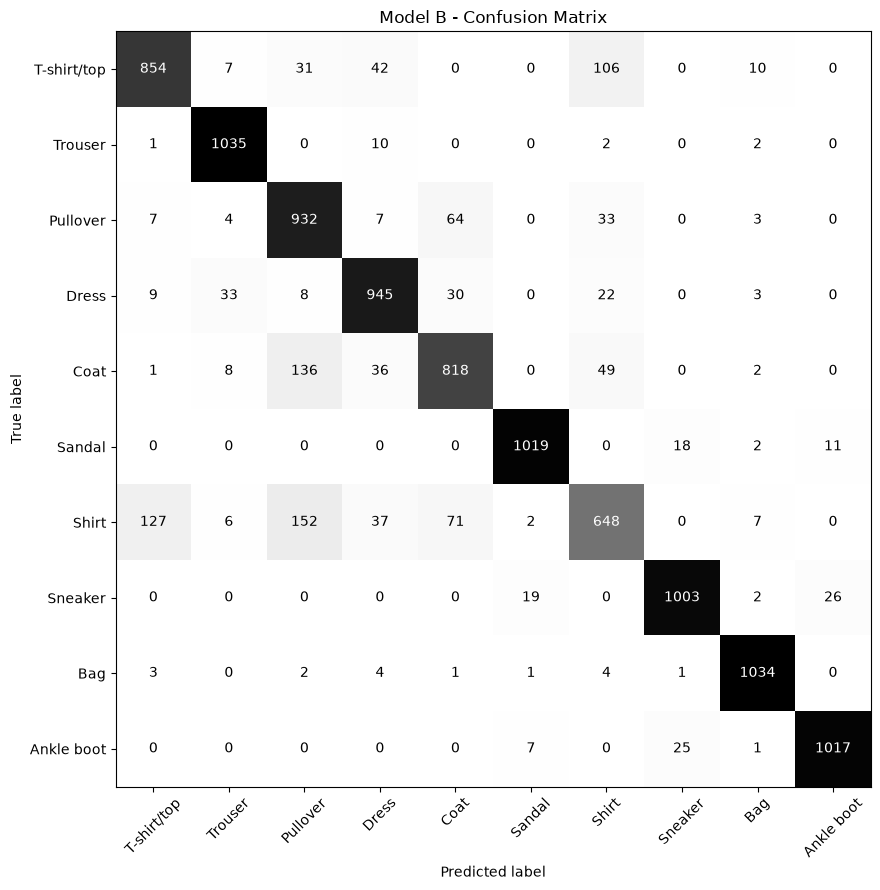

In [19]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Greys",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Model B - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "model_B_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


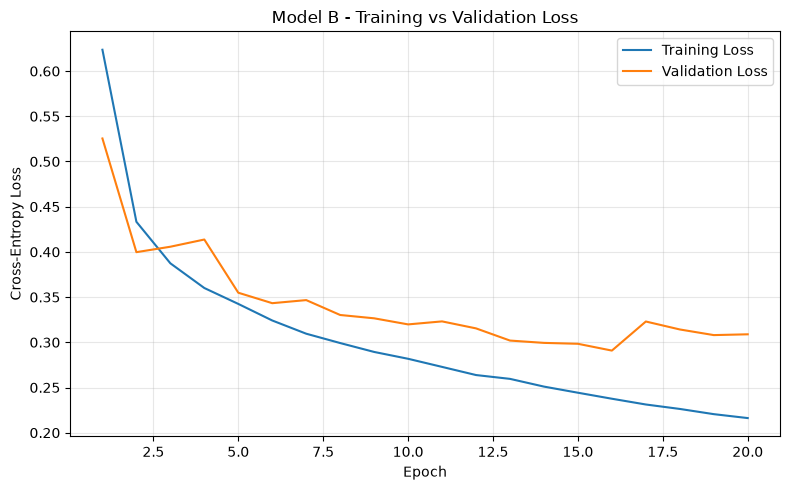

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 21),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, 21),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Model B - Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "model_B_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [22]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results_B = pd.DataFrame({
    "Model": ["Depthwise Separable CNN"],
    "Accuracy (%)": [
        accuracy_score(all_true_labels, all_predictions) * 100
    ],
    "Precision (%)": [
        precision_score(all_true_labels, all_predictions, average="macro") * 100
    ],
    "Recall (%)": [
        recall_score(all_true_labels, all_predictions, average="macro") * 100
    ],
    "F1 (%)": [
        f1_score(all_true_labels, all_predictions, average="macro") * 100
    ]
})

display(results_B.round(2))

results_B.to_csv(
    "model_B_evaluation_results.csv",
    index=False
)

,Model,Accuracy (%),Precision (%),Recall (%),F1 (%)
0,Depthwise Separable CNN,88.62,88.59,88.62,88.45


### Model B Performance Discussion

The training loss decreased consistently across the 20 epochs,
indicating successful learning. The validation loss initially
decreased before stabilizing after approximately 10-12 epochs.
A small increase in validation loss toward the final epochs
suggests mild overfitting.

The final test performance was evaluated using accuracy,
macro-averaged precision, recall, F1-score, and a confusion
matrix.

The confusion matrix was used to identify the classes that
were most frequently misclassified.

# Model A: Standard CNN Training and Evaluation

This section trains and evaluates Model A (Standard CNN)
using the same 70/15/15 Fashion-MNIST dataset split
used for Model B.

Both models are evaluated using the same test dataset
to ensure a fair comparison.

In [23]:
torch.manual_seed(42)

trained_model_A = Standard_CNN().to(device)

criterion_A = nn.CrossEntropyLoss()

optimizer_A = torch.optim.Adam(
    trained_model_A.parameters(),
    lr=0.001
)

print("Model A initialized successfully!")

Model A initialized successfully!


In [24]:
import time

epochs = 20

train_losses_A = []
val_losses_A = []
val_accuracies_A = []
epoch_times_A = []

for epoch in range(epochs):

    start_time = time.perf_counter()

    trained_model_A.train()
    running_train_loss = 0.0

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_A.zero_grad()

        outputs = trained_model_A(images)
        loss = criterion_A(outputs, labels)

        loss.backward()
        optimizer_A.step()

        running_train_loss += loss.item() * images.size(0)

    avg_train_loss = running_train_loss / len(train_dataset)
    train_losses_A.append(avg_train_loss)

    trained_model_A.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = trained_model_A(images)
            loss = criterion_A(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = running_val_loss / len(val_dataset)
    val_accuracy = 100 * correct / total

    val_losses_A.append(avg_val_loss)
    val_accuracies_A.append(val_accuracy)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time
    epoch_times_A.append(elapsed)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Time: {elapsed:.2f}s"
    )

Epoch 1/20 | Train Loss: 0.5660 | Val Loss: 0.4118 | Val Acc: 84.30% | Time: 18.64s
Epoch 2/20 | Train Loss: 0.3840 | Val Loss: 0.3692 | Val Acc: 86.27% | Time: 18.13s
Epoch 3/20 | Train Loss: 0.3365 | Val Loss: 0.3225 | Val Acc: 87.88% | Time: 18.23s
Epoch 4/20 | Train Loss: 0.3082 | Val Loss: 0.3052 | Val Acc: 88.58% | Time: 18.37s
Epoch 5/20 | Train Loss: 0.2907 | Val Loss: 0.3030 | Val Acc: 88.23% | Time: 18.20s
Epoch 6/20 | Train Loss: 0.2763 | Val Loss: 0.2846 | Val Acc: 89.30% | Time: 18.18s
Epoch 7/20 | Train Loss: 0.2625 | Val Loss: 0.2781 | Val Acc: 89.68% | Time: 18.14s
Epoch 8/20 | Train Loss: 0.2537 | Val Loss: 0.2874 | Val Acc: 89.73% | Time: 17.71s
Epoch 9/20 | Train Loss: 0.2450 | Val Loss: 0.3014 | Val Acc: 88.96% | Time: 19.83s
Epoch 10/20 | Train Loss: 0.2374 | Val Loss: 0.2736 | Val Acc: 90.01% | Time: 20.87s
Epoch 11/20 | Train Loss: 0.2288 | Val Loss: 0.2677 | Val Acc: 90.21% | Time: 19.88s
Epoch 12/20 | Train Loss: 0.2227 | Val Loss: 0.2583 | Val Acc: 90.85% | Ti

In [26]:
trained_model_A.eval()

predictions_A = []
true_labels_A = []

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)

        outputs = trained_model_A(images)
        predictions = outputs.argmax(dim=1)

        predictions_A.extend(predictions.cpu().numpy())
        true_labels_A.extend(labels.numpy())

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_A = accuracy_score(true_labels_A, predictions_A)
precision_A = precision_score(
    true_labels_A, predictions_A, average="macro"
)
recall_A = recall_score(
    true_labels_A, predictions_A, average="macro"
)
f1_A = f1_score(
    true_labels_A, predictions_A, average="macro"
)

print(f"Model A Accuracy:  {accuracy_A*100:.2f}%")
print(f"Model A Precision: {precision_A*100:.2f}%")
print(f"Model A Recall:    {recall_A*100:.2f}%")
print(f"Model A F1-score:  {f1_A*100:.2f}%")

print(classification_report(
    true_labels_A,
    predictions_A,
    target_names=class_names
))

Model A Accuracy:  90.48%
Model A Precision: 90.45%
Model A Recall:    90.48%
Model A F1-score:  90.43%
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.85      0.85      1050
     Trouser       0.98      0.99      0.99      1050
    Pullover       0.83      0.87      0.85      1050
       Dress       0.89      0.94      0.91      1050
        Coat       0.86      0.82      0.84      1050
      Sandal       0.97      0.97      0.97      1050
       Shirt       0.76      0.72      0.74      1050
     Sneaker       0.93      0.98      0.95      1050
         Bag       0.99      0.98      0.99      1050
  Ankle boot       0.98      0.93      0.96      1050

    accuracy                           0.90     10500
   macro avg       0.90      0.90      0.90     10500
weighted avg       0.90      0.90      0.90     10500



In [28]:
torch.save(
    trained_model_A.state_dict(),
    "checkpoints/model_A_20epochs.pth"
)

print("Model A checkpoint saved!")

Model A checkpoint saved!


In [29]:
comparison_table = pd.DataFrame({
    "Model": ["Standard CNN", "Depthwise Separable CNN"],
    "Parameters": [params_A, params_B],
    "Estimated Weight Size (KB)": [size_A, size_B],
    "Test Accuracy (%)": [accuracy_A * 100, accuracy_B * 100],
    "Macro Precision (%)": [precision_A * 100, precision_B * 100],
    "Macro Recall (%)": [recall_A * 100, recall_B * 100],
    "Macro F1 (%)": [f1_A * 100, f1_B * 100]
})

display(comparison_table.round(2))

comparison_table.to_csv(
    "CNN_comparison_results.csv",
    index=False
)

,Model,Parameters,Estimated Weight Size (KB),Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,Standard CNN,42838,167.34,90.48,90.45,90.48,90.43
1,Depthwise Separable CNN,42106,164.48,88.62,88.59,88.62,88.45


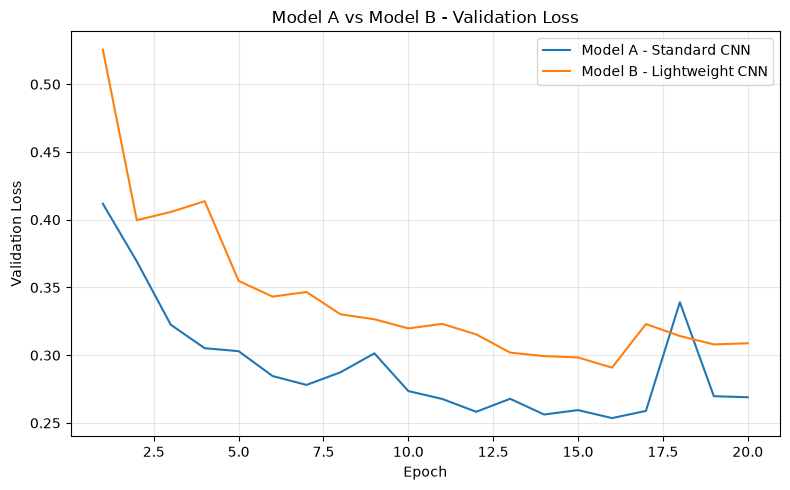

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 21),
    val_losses_A,
    label="Model A - Standard CNN"
)

plt.plot(
    range(1, 21),
    val_losses,
    label="Model B - Lightweight CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Model A vs Model B - Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "CNN_validation_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Training Time Benchmark

To compare the computational efficiency of the standard CNN
and depthwise separable CNN, both architectures are
benchmarked using the same hardware, dataset, batch size,
optimizer, and number of training batches.

The benchmark measures training time per epoch.

In [31]:
import time
import numpy as np
import torch
import torch.nn as nn

def benchmark_training(model_class, loader, device, batches=100):

    torch.manual_seed(42)

    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    processed_batches = 0

    for images, labels in loader:

        if processed_batches >= batches:
            break

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        processed_batches += 1

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return elapsed, processed_batches


In [32]:
time_A, batches_A = benchmark_training(
    Standard_CNN,
    trainloader,
    device
)

time_B, batches_B = benchmark_training(
    DepthWise_Separable_CNN,
    trainloader,
    device
)

print(f"Model A: {time_A:.2f} seconds for {batches_A} batches")
print(f"Model B: {time_B:.2f} seconds for {batches_B} batches")


Model A: 1.92 seconds for 100 batches
Model B: 2.24 seconds for 100 batches


In [33]:
total_batches = len(trainloader)

estimated_epoch_A = time_A / batches_A * total_batches
estimated_epoch_B = time_B / batches_B * total_batches

benchmark_results = pd.DataFrame({
    "Model": ["Standard CNN", "Depthwise Separable CNN"],
    "Benchmark Time (s)": [time_A, time_B],
    "Estimated Training Time/Epoch (s)": [
        estimated_epoch_A,
        estimated_epoch_B
    ]
})

display(benchmark_results.round(2))

benchmark_results.to_csv(
    "CNN_training_time_benchmark.csv",
    index=False
)


,Model,Benchmark Time (s),Estimated Training Time/Epoch (s)
0,Standard CNN,1.92,18.86
1,Depthwise Separable CNN,2.24,21.97


## Discussion: Standard CNN vs Depthwise Separable CNN

### 1. Classification Performance

Both models were trained for **20 epochs** using the same Fashion-MNIST dataset split and Adam optimizer with a learning rate of **0.001**.

Model A (Standard CNN) achieved a test accuracy of **90.48%**, while Model B (Depthwise Separable CNN) achieved **88.62%**. Model A also obtained slightly higher precision, recall, and F1-score.

These results indicate that the standard CNN performed better at classifying clothing images in this experiment. Although Model B uses depthwise separable convolutions to reduce computational complexity, this did not result in higher classification accuracy.

### 2. Parameter Count and Memory Usage

Model A contained **42,838 trainable parameters**, while Model B contained **42,106**, representing a **1.71% reduction**. The estimated weight memory also decreased from **167.34 KB to 164.48 KB**.

The reduction is relatively small because both architectures contain fully connected layers that account for a substantial portion of their parameters. Therefore, replacing standard convolutions with depthwise separable convolutions does not necessarily produce a large reduction in the total model size.

Nevertheless, Model B satisfies the assignment's constraint of fewer than **100,000 trainable parameters**.

### 3. Training Efficiency

The training-time benchmark was performed on the same CPU using identical batch sizes and training settings.

- **Model A:** 18.86 seconds per epoch
- **Model B:** 21.97 seconds per epoch

Although depthwise separable convolutions generally require fewer multiply-accumulate operations than standard convolutions, Model B was approximately **16.5% slower** in this benchmark.

This may be due to implementation overhead and the efficiency of the individual convolution operations on the CPU.

These results demonstrate that a reduction in theoretical computational complexity does not always translate into faster execution on a particular hardware platform.

### 4. Training and Validation Loss

The training and validation loss curves show that both models successfully learned from the dataset.

For Model B, the training loss continued to decrease throughout the 20 epochs, while the validation loss stabilized and increased slightly toward the end, suggesting **mild overfitting**.

The validation loss comparison also provides insight into the learning behavior of both architectures and helps explain differences in their classification performance.

### 5. Overall Trade-off

Model A provided better classification accuracy and faster CPU training, whereas Model B offered a slightly smaller parameter count and estimated memory footprint.

For this particular dataset and experimental setup, **Model A demonstrated a more favorable balance of accuracy and measured training speed**.

However, Model B remains useful for investigating resource-efficient architectures, particularly where memory usage and theoretical computational cost are important considerations.

Further evaluation of **multiply-accumulate operations (MACs), inference latency, and deployment memory** would be necessary to determine which architecture is more suitable for actual edge-device deployment.